In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

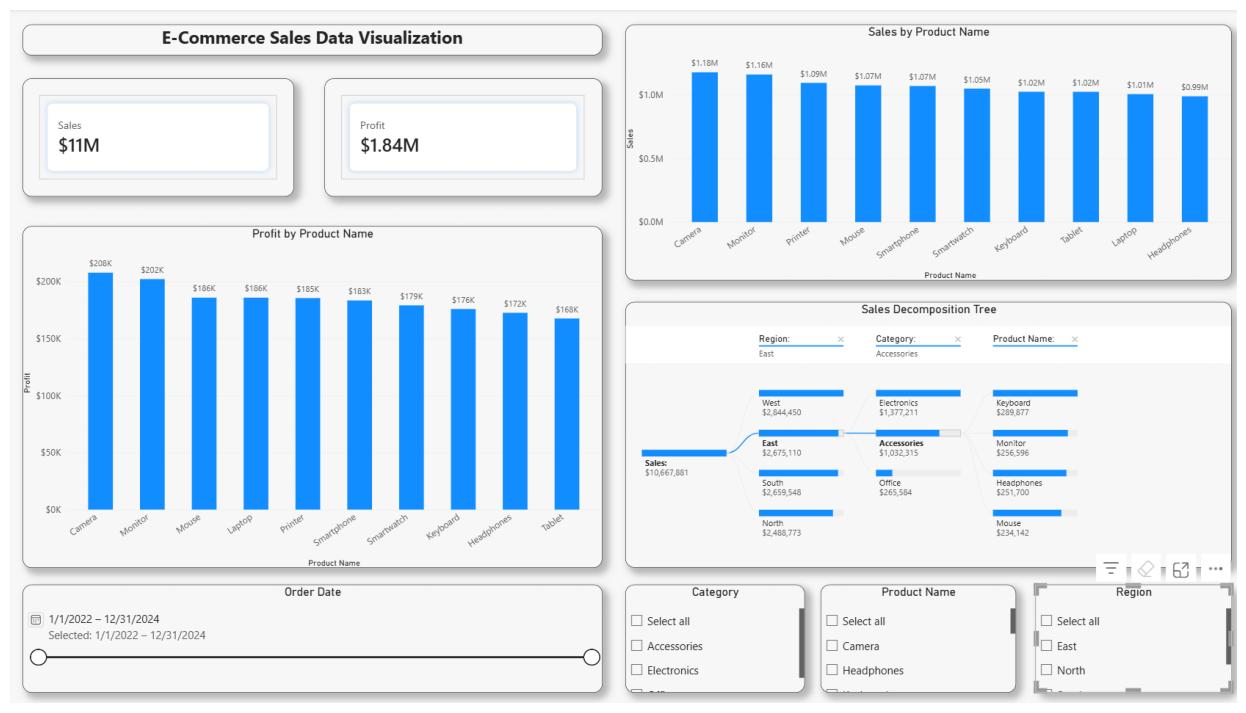

In [51]:
# Dashbord Screenshot
import matplotlib.image as mpltimg
img = mpltimg.imread(f"Screenshot 2026-10-12 213059.png")
plt.figure(figsize=(18, 9))
plt.imshow(img)
plt.axis('off')
plt.show()

In [28]:
# loading the data

data = pd.read_csv("ecommerce_sales_data.csv")

data

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
0,12/31/2024,Printer,Office,North,4,3640,348.93
1,11/27/2022,Mouse,Accessories,East,7,1197,106.53
2,5/11/2022,Tablet,Electronics,South,5,5865,502.73
3,3/16/2024,Mouse,Accessories,South,2,786,202.87
4,9/10/2022,Mouse,Accessories,West,1,509,103.28
...,...,...,...,...,...,...,...
3495,2/15/2023,Monitor,Accessories,North,4,4064,771.16
3496,9/18/2022,Monitor,Accessories,East,1,1117,119.89
3497,4/12/2022,Laptop,Electronics,South,4,260,66.02
3498,1/18/2022,Printer,Office,South,3,222,50.28


The goal is to analyze this small dataset and see which product and which region did the best sales and profits.

In [29]:
# EDA
## DataFrame Summary
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order Date    3500 non-null   str    
 1   Product Name  3500 non-null   str    
 2   Category      3500 non-null   str    
 3   Region        3500 non-null   str    
 4   Quantity      3500 non-null   int64  
 5   Sales         3500 non-null   int64  
 6   Profit        3500 non-null   float64
dtypes: float64(1), int64(2), str(4)
memory usage: 191.5 KB


In [30]:
# Which product had the most in sales and profit

product_sales_profit = data[['Product Name', 'Quantity', 'Sales', 'Profit']]

group_by_product = product_sales_profit.groupby(['Product Name'])[['Quantity','Sales', 'Profit']].sum()
group_by_product = group_by_product.reset_index()
group_by_product

,Product Name,Quantity,Sales,Profit
0,Camera,1795,1177381,207630.99
1,Headphones,1604,988638,172478.20
2,Keyboard,1684,1024507,175814.68
3,Laptop,1658,1005873,185756.81
4,Monitor,1876,1160048,202028.17
5,Mouse,1753,1074398,185763.69
6,Printer,1734,1094216,185394.88
7,Smartphone,1617,1069681,183296.97
8,Smartwatch,1807,1049211,178995.81
9,Tablet,1733,1023928,167505.01


In [31]:
# sorting for vizualization
sorted_by_sales = group_by_product.sort_values('Sales', ascending=False)
sorted_by_profit = group_by_product.sort_values('Profit', ascending=False)
sorted_by_quantity = group_by_product.sort_values('Quantity', ascending=False)

#test
sorted_by_profit.head(), sorted_by_quantity.head(), sorted_by_sales.head()

(  Product Name  Quantity    Sales     Profit
 0       Camera      1795  1177381  207630.99
 4      Monitor      1876  1160048  202028.17
 5        Mouse      1753  1074398  185763.69
 3       Laptop      1658  1005873  185756.81
 6      Printer      1734  1094216  185394.88,
   Product Name  Quantity    Sales     Profit
 4      Monitor      1876  1160048  202028.17
 8   Smartwatch      1807  1049211  178995.81
 0       Camera      1795  1177381  207630.99
 5        Mouse      1753  1074398  185763.69
 6      Printer      1734  1094216  185394.88,
   Product Name  Quantity    Sales     Profit
 0       Camera      1795  1177381  207630.99
 4      Monitor      1876  1160048  202028.17
 6      Printer      1734  1094216  185394.88
 5        Mouse      1753  1074398  185763.69
 7   Smartphone      1617  1069681  183296.97)

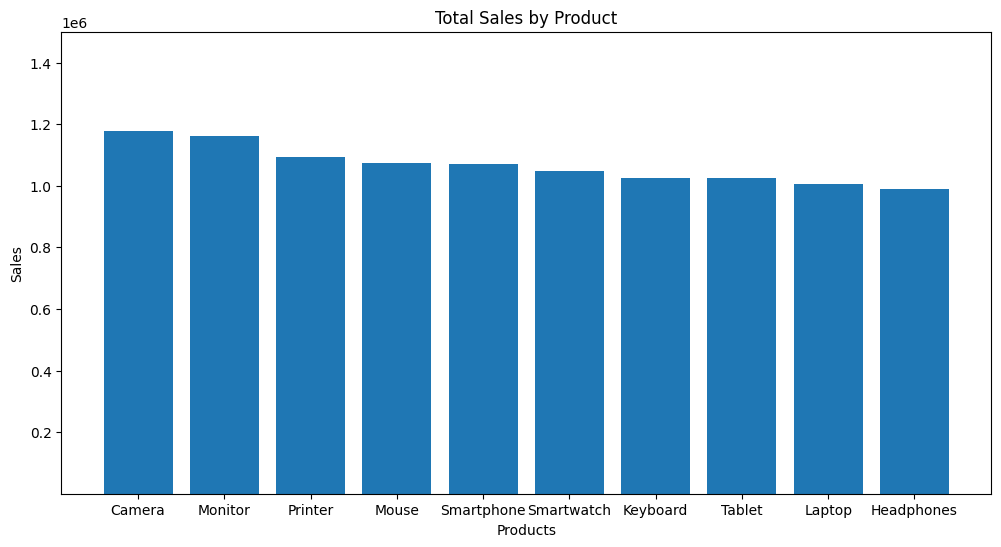

In [32]:
# Sales Visualization
plt.figure(figsize=(12, 6))
plt.bar(sorted_by_sales['Product Name'], sorted_by_sales['Sales'], width=0.8)
plt.xlabel("Products")
plt.ylabel("Sales")
plt.ylim(1, 1500000)
plt.title("Total Sales by Product")
plt.show()

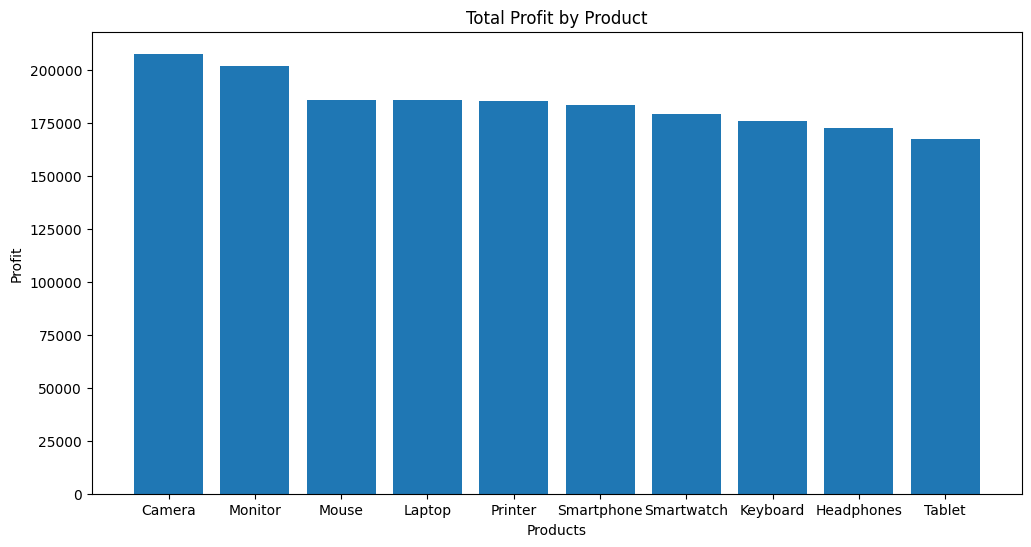

In [33]:
# Profit Visualization
plt.figure(figsize=(12, 6))
plt.bar(sorted_by_profit['Product Name'], sorted_by_profit['Profit'], width=0.8)
plt.xlabel("Products")
plt.ylabel("Profit")
plt.title("Total Profit by Product")
plt.show()

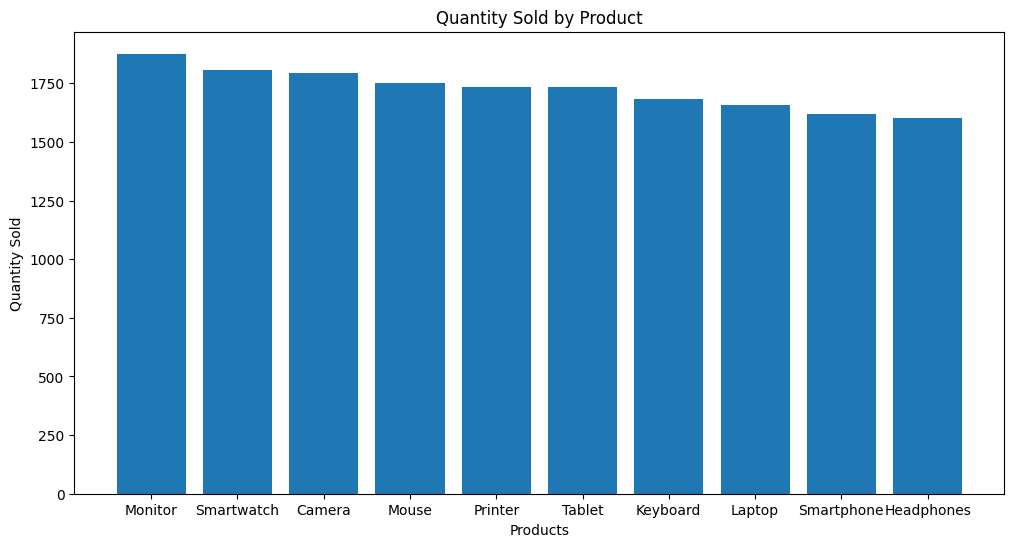

In [34]:
# Quantity Sold Visualization
plt.figure(figsize=(12, 6))
plt.bar(sorted_by_quantity['Product Name'], sorted_by_quantity['Quantity'], width=0.8)
plt.xlabel("Products")
plt.ylabel("Quantity Sold")
plt.title("Quantity Sold by Product")
plt.show()

In [35]:
# Let's look at regions
regions_sales_profit = data[['Region', 'Quantity', 'Sales', 'Profit']]

group_by_region = regions_sales_profit.groupby(['Region'])[['Quantity','Sales', 'Profit']].sum()
group_by_region = group_by_region.reset_index()
group_by_region

,Region,Quantity,Sales,Profit
0,East,4306,2675110,464888.46
1,North,4106,2488773,426314.75
2,South,4361,2659548,458103.27
3,West,4488,2844450,495358.73


In [36]:
sorted_for_sales = group_by_region.sort_values('Sales', ascending=False)
sorted_for_profit = group_by_region.sort_values('Profit', ascending=False)
sorted_for_quantity = group_by_region.sort_values('Quantity', ascending=False)

#test
sorted_for_profit.head(), sorted_for_quantity.head(), sorted_for_sales.head()

(  Region  Quantity    Sales     Profit
 3   West      4488  2844450  495358.73
 0   East      4306  2675110  464888.46
 2  South      4361  2659548  458103.27
 1  North      4106  2488773  426314.75,
   Region  Quantity    Sales     Profit
 3   West      4488  2844450  495358.73
 2  South      4361  2659548  458103.27
 0   East      4306  2675110  464888.46
 1  North      4106  2488773  426314.75,
   Region  Quantity    Sales     Profit
 3   West      4488  2844450  495358.73
 0   East      4306  2675110  464888.46
 2  South      4361  2659548  458103.27
 1  North      4106  2488773  426314.75)

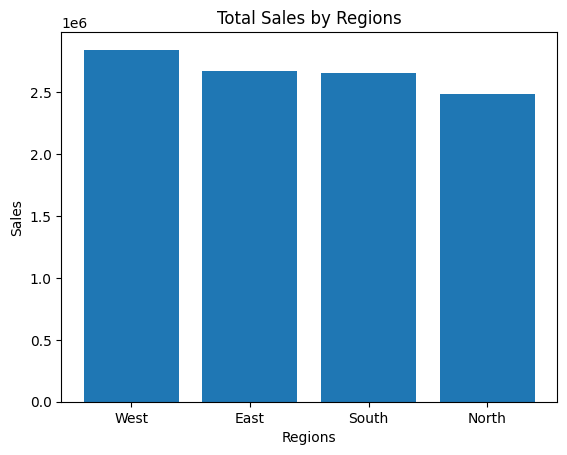

In [37]:
# Sales Visualization by Regions

plt.bar(sorted_for_sales['Region'], sorted_for_sales['Sales'], width=0.8)
plt.xlabel("Regions")
plt.ylabel("Sales")
plt.title("Total Sales by Regions")
plt.show()

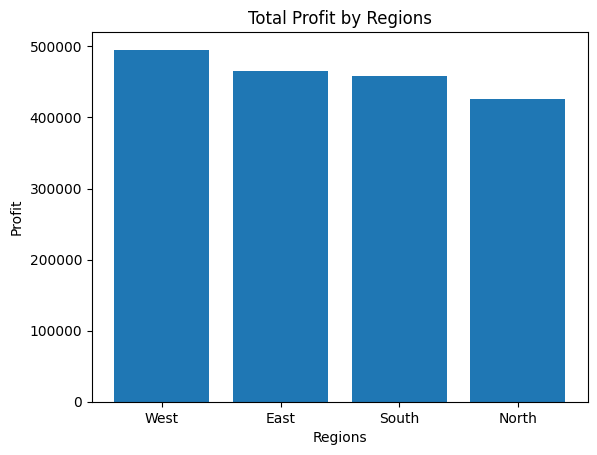

In [38]:
# Profit Visualization by Regions

plt.bar(sorted_for_profit['Region'], sorted_for_profit['Profit'], width=0.8)
plt.xlabel("Regions")
plt.ylabel("Profit")
plt.title("Total Profit by Regions")
plt.show()

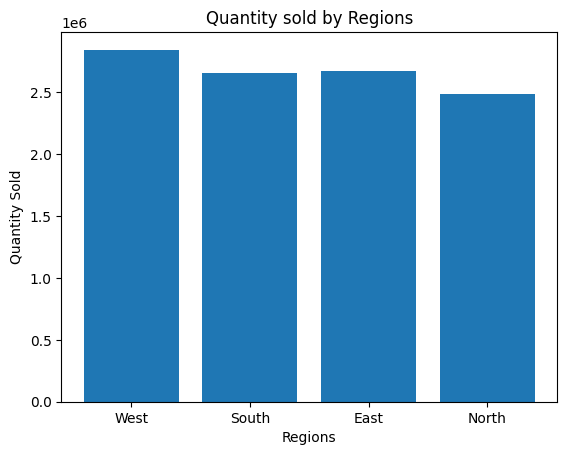

In [39]:
# Quantity Sold Visualization by Regions

plt.bar(sorted_for_quantity['Region'], sorted_for_quantity['Sales'], width=0.8)
plt.xlabel("Regions")
plt.ylabel("Quantity Sold")
plt.title("Quantity sold by Regions")
plt.show()

In [40]:
# Let's look at sales and profit by year

#sort by order date
sort_by_year = data.sort_values('Order Date')
sort_by_year['Order Date'] = pd.to_datetime(sort_by_year['Order Date'])
sort_by_year

,Order Date,Product Name,Category,Region,Quantity,Sales,Profit
2994,2022-01-01,Headphones,Accessories,South,7,3941,628.96
1563,2022-01-01,Keyboard,Accessories,East,6,6372,570.75
875,2022-01-01,Monitor,Accessories,South,8,1296,273.97
106,2022-01-01,Mouse,Accessories,East,3,3474,565.00
2841,2022-01-01,Tablet,Electronics,North,9,9234,2523.67
...,...,...,...,...,...,...,...
1057,2024-09-09,Smartwatch,Electronics,West,5,705,198.62
1899,2024-09-09,Smartphone,Electronics,South,5,4370,1255.36
2848,2024-09-09,Camera,Electronics,East,2,1054,243.50
344,2024-09-09,Smartphone,Electronics,East,2,2258,280.76


In [41]:
# Set order date as index
sort_by_yearI = sort_by_year.set_index('Order Date')
sort_by_yearI.head()

,Product Name,Category,Region,Quantity,Sales,Profit
Order Date,,,,,,
2022-01-01,Headphones,Accessories,South,7,3941,628.96
2022-01-01,Keyboard,Accessories,East,6,6372,570.75
2022-01-01,Monitor,Accessories,South,8,1296,273.97
2022-01-01,Mouse,Accessories,East,3,3474,565.00
2022-01-01,Tablet,Electronics,North,9,9234,2523.67


In [42]:
year_2022 = sort_by_yearI.loc['2022'][['Sales', 'Profit']].sum()
year_2023 = sort_by_yearI.loc['2023'][['Sales', 'Profit']].sum()
year_2024 = sort_by_yearI.loc['2024'][['Sales', 'Profit']].sum()
print(f"2022\n{year_2022.to_string()} \n2023\n{year_2023.to_string()} \n2024\n{year_2024.to_string()}")

2022
Sales     3255970.00
Profit     572856.98 
2023
Sales     3786592.00
Profit     666866.42 
2024
Sales     3625319.00
Profit     604941.81


Cameras made the most in sales and profit, however Monitors had the most sold items.

The West region had the most sale, profit, and and items sold.

2023 was the most profitable year followed by 2024 and 2022.